# Immune cells in the breast tumor microenvironment: a 10x Xenium analysis

**Question:** In this breast cancer section, do immune cells infiltrate the tumor, or are they held back in the surrounding stroma?

**Data:** 10x Genomics Xenium In Situ, FFPE human breast cancer, replicate 1 (313-gene panel, ~168,000 cells), from Janesick et al., *Nature Communications* 2023 ([paper](https://www.nature.com/articles/s41467-023-43458-x)). Downloaded as `xenium_rep1_io` from the [SpatialData example datasets](https://spatialdata.scverse.org/en/stable/tutorials/notebooks/datasets/README.html) (CC BY 4.0).

## Setup

The data folder (`data/xenium.zarr`, ~3.4 GB) was downloaded as `xenium_rep1_io` from the link above, unzipped, renamed to `xenium.zarr` and placed in `data/`.

In [1]:
from importlib.metadata import version
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse
from scipy.spatial import cKDTree

import scanpy as sc
import spatialdata as sd
import squidpy as sq
import spatialdata_plot  # noqa: F401  (adds the .pl plotting methods to SpatialData)

DATA_DIR = Path("../data")
FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)

for pkg in ["scanpy", "squidpy", "spatialdata", "anndata", "scipy"]:
    print(f"{pkg:12s} {version(pkg)}")

/opt/anaconda3/envs/spatial/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


scanpy       1.11.5
squidpy      1.8.2
spatialdata  0.7.3
anndata      0.12.19
scipy        1.14.1


/opt/anaconda3/envs/spatial/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/opt/anaconda3/envs/spatial/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


**Compatibility fix.** With SciPy >= 1.14, `sc.pp.neighbors` in scanpy 1.11 fails with `'csr_array' object has no attribute 'getnnz'`, because SciPy removed that method from its sparse arrays. The cell below adds the method back (it counts the stored values in each row of a sparse table). It can be removed once a newer scanpy no longer calls `getnnz`.

In [2]:
if not hasattr(sparse.csr_array, "getnnz"):
    def _getnnz(self, axis=None):
        if axis is None:
            return self.nnz
        if axis == 1:
            return np.diff(self.indptr)                             # non-zeros per row
        return np.bincount(self.indices, minlength=self.shape[1])   # non-zeros per column
    sparse.csr_array.getnnz = _getnnz

## Part 1: The tissue and the segmentation

### Biology needed for this tissue

A breast is a branching network of milk **ducts** surrounded by supporting tissue, the **stroma**. Each duct is lined by **luminal epithelial cells** (where most breast cancers start) and wrapped by a thin outer layer of **myoepithelial cells** sitting on a basement membrane. The stroma contains fibroblasts, blood vessels, fat and immune cells.

- In **DCIS** (ductal carcinoma in situ), cancer cells fill the duct but the myoepithelial layer is still intact, so the cancer is contained.
- In **invasive carcinoma**, cancer cells break through that layer into the stroma, where they can reach blood and lymph vessels.

So the presence or absence of a myoepithelial ring around tumor cells is informative, and it can be seen in spatial data.

### Loading the data

A SpatialData object holds every element of the experiment in one place, with shared coordinates.

In [3]:
sdata = sd.read_zarr(DATA_DIR / "xenium.zarr")
sdata

SpatialData object, with associated Zarr store: /Users/pranavasri_rm/Desktop/projects/xenium-breast-tme/data/xenium.zarr
├── Images
│     ├── 'morphology_focus': DataTree[cyx] (1, 25778, 35416), (1, 12889, 17708), (1, 6444, 8854), (1, 3222, 4427), (1, 1611, 2213)
│     └── 'morphology_mip': DataTree[cyx] (1, 25778, 35416), (1, 12889, 17708), (1, 6444, 8854), (1, 3222, 4427), (1, 1611, 2213)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 8) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (167780, 1) (2D shapes)
│     ├── 'cell_circles': GeoDataFrame shape: (167780, 2) (2D shapes)
│     └── 'xenium_landmarks': GeoDataFrame shape: (3, 2) (2D shapes)
└── Tables
      └── 'table': AnnData (167780, 313)
with coordinate systems:
    ▸ 'aligned', with elements:
        morphology_focus (Images)
    ▸ 'global', with elements:
        morphology_focus (Images), morphology_mip (Images), transcripts (Points), cell_boundaries (Shapes), cell_circles (Sh

The object has four kinds of elements:

- **Images:** `morphology_focus` is the DAPI image, which stains DNA, so it shows **nuclei only** (no cell membranes). Its shape `(1, 25778, 35416)` is channels × height × width in pixels. It's stored as a pyramid of five resolutions so plots load quickly: a low resolution for the whole slide, full resolution when zoomed in.
- **Points:** `transcripts`, every detected RNA molecule with its x, y, z position and gene. It's loaded lazily (`<Delayed>`) because there are tens of millions.
- **Shapes:** `cell_boundaries`, the cell outlines produced by the 10x onboard software (the "default" segmentation).
- **Tables:** `table`, an AnnData of 167,780 cells × 313 genes. Each value is the number of transcripts of a gene that fell **inside a cell's outline**.

Because the table is built by counting transcripts inside outlines, its quality depends directly on the segmentation.

The elements are linked through **coordinate systems**. A coordinate system is a named reference frame, plus the transformation that places each element in it. In `global`, the image, transcripts and outlines all line up in image pixel units (1 pixel ~ 0.2125 µm).

### The whole slide

{'y': (np.float64(0.0), np.float64(25778.0)), 'x': (np.float64(0.0), np.float64(35416.0))}


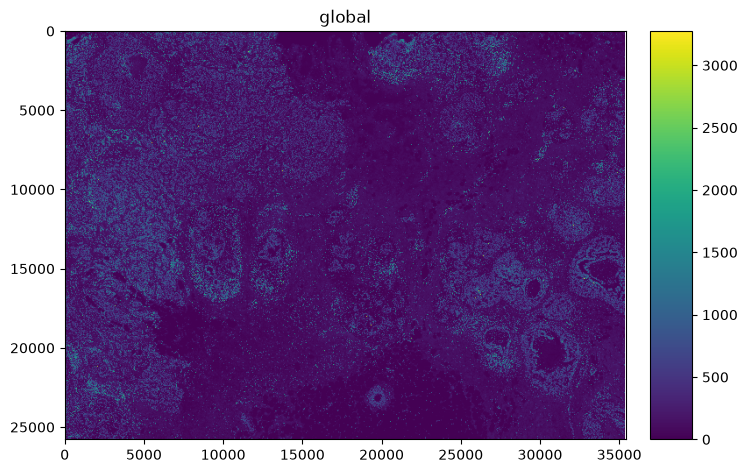

In [4]:
# whole slide
sdata.pl.render_images("morphology_focus").pl.show(coordinate_systems="global")

# how big is it? (units of the 'global' coordinate system)
print(sd.get_extent(sdata["morphology_focus"]))

Brightness is DAPI intensity, so bright areas are packed with nuclei and dark areas have few cells. The slide is about 7.5 × 5.5 mm (35,416 × 25,778 pixels). Large rounded structures on the right (around x 25,000 to 33,000, y 14,000 to 20,000 pixels) look like ducts. The dense textured areas on the left look like solid tissue, and the darker areas in between have fewer cells (stroma or fat). These are guesses from nuclei alone; Part 4 checks them against cell types.

### Zooming in: how good are the cell outlines?

The function below plots the DAPI image with the default cell outlines for a square window, in pixel coordinates. Dropping the transcripts first (`subset`) keeps the query fast.

In [5]:
def show_crop(sdata, x0, y0, size=1500, title=None, save=None):
    """Plot DAPI plus default cell outlines in a square window (pixel coordinates)."""
    small = sdata.subset(['morphology_focus', "cell_boundaries"])
    crop = small.query.bounding_box(
        axes=("x", "y"),
        min_coordinate=[x0, y0],
        max_coordinate=[x0 + size, y0 + size],
        target_coordinate_system="global",
    )
    fig, ax = plt.subplots(figsize=(6, 6))
    (
        crop.pl.render_images("morphology_focus")
        .pl.render_shapes("cell_boundaries", fill_alpha=0, outline_alpha=0.7)
        .pl.show(coordinate_systems="global", ax=ax, title=title)
    )
    if save:
        fig.savefig(save, dpi=200, bbox_inches="tight")

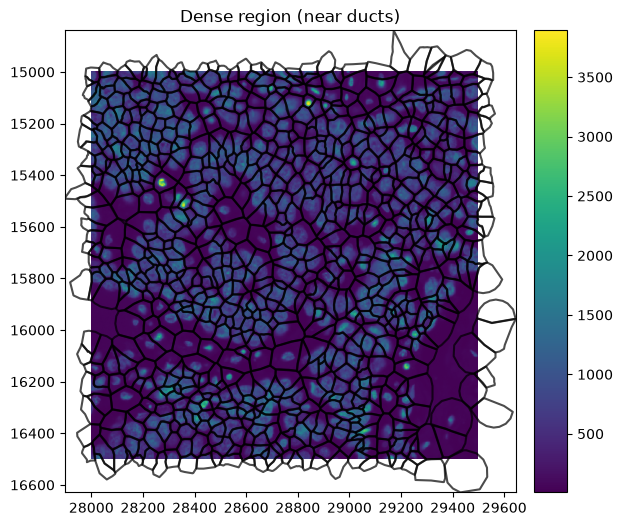

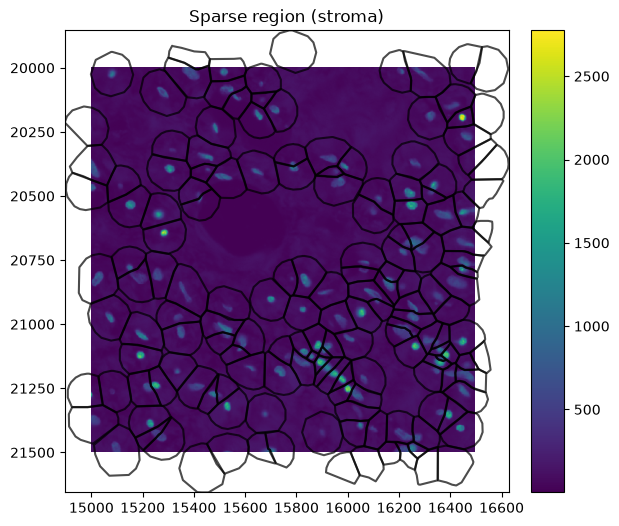

In [6]:
show_crop(sdata, 28000, 15000, title="Dense region (near ducts)", save=FIG_DIR / "crop_dense.png")
show_crop(sdata, 15000, 20000, title="Sparse region (stroma)", save=FIG_DIR / "crop_sparse.png")

- **Dense region:** nuclei are tightly packed, and the outlines tile around them like a honeycomb. Neighbors limit how far each outline grows, so outlines roughly fit the cells. Their borders are where two expansions met, though, not real membranes.
- **Sparse region:** nuclei are sparse and elongated, consistent with stromal fibroblasts. Outlines are several times larger than the nuclei and include empty tissue.

**Why the outlines are too big:** this dataset has a nuclear stain only. The 10x software found each nucleus in the DAPI image and expanded it outward by a certain distance, until it met a neighbor's expansion. In sparse tissue nothing stops the expansion, so outlines balloon. Any transcript inside an inflated outline is counted for that cell, even if it came from a neighbor. This is called **transcript spillover**, and it can make a cell look like a mixture of two cell types.

### Measuring how much the outlines are inflated

,cell_area,nucleus_area
count,167780.000000,167780.000000
mean,193.674988,43.080427
std,174.436086,30.677698
min,5.192969,3.206094
25%,86.022656,22.081406
50%,140.300469,33.235000
75%,229.529219,57.303281
max,1532.738594,392.498125


Median cell/nucleus area ratio: 3.40
Cells with ratio > 5:  35.2%
Cells with ratio >= 20: 6.6%


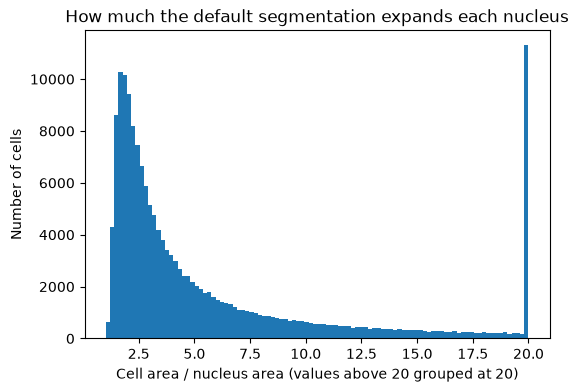

In [7]:
cells_raw = sdata.tables["table"].obs   # read-only look at the raw per-cell info; adata is left untouched

areas = cells_raw[["cell_area", "nucleus_area"]]
display(areas.describe())

ratio = cells_raw["cell_area"] / cells_raw["nucleus_area"]
print(f"Median cell/nucleus area ratio: {ratio.median():.2f}")
print(f"Cells with ratio > 5:  {(ratio > 5).mean():.1%}")
print(f"Cells with ratio >= 20: {(ratio >= 20).mean():.1%}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(ratio.clip(upper=20), bins=100)
ax.set_xlabel("Cell area / nucleus area (values above 20 grouped at 20)")
ax.set_ylabel("Number of cells")
ax.set_title("How much the default segmentation expands each nucleus")
fig.savefig(FIG_DIR / "area_ratio.png", dpi=200, bbox_inches="tight")

The median cell outline is 3.4x its nucleus area, which is plausible for real cells. But 35% of cells exceed 5x, and 6.6% exceed 20x: those "cells" are mostly expansion. (In the histogram, values above 20 are clipped to 20, so they pile up in the last bar instead of stretching the axis.) These are the cells most at risk of spillover.

## Part 2: Quality control, normalization and clustering

The aim of this part is to find groups of cells with similar expression. The workflow is the same as for single-cell RNA-seq, with three differences:

- **Targeted panel:** 313 pre-selected genes, not the whole transcriptome, so there are far fewer transcripts per cell.
- **Cells come from segmentation,** not droplets. A "bad cell" can be a bad outline: two cells merged, a cell cut by the section, or an inflated outline.
- **Noise is measured with control probes**, which target sequences absent from human cells, rather than mitochondrial reads.

I take an independent copy of the table, so that `sdata` keeps the original data for plotting later.

In [8]:
adata = sdata.tables["table"].copy()
print(adata)
adata.obs.head()

AnnData object with n_obs × n_vars = 167780 × 313
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatialdata_attrs'
    obsm: 'spatial'


,cell_id,transcript_counts,control_probe_counts,control_codeword_counts,total_counts,cell_area,nucleus_area,region
1,1,28,1,0,29,58.387031,26.642188,cell_circles
2,2,94,0,0,94,197.016719,42.130781,cell_circles
3,3,9,0,0,9,16.256250,12.688906,cell_circles
4,4,11,0,0,11,42.311406,10.069844,cell_circles
5,5,48,0,0,48,107.652500,37.479688,cell_circles


`adata.X` holds the counts (cells × genes). `obs` has one row of information per cell, `var` one row per gene, and `obsm["spatial"]` stores each cell's x, y position.

Xenium adds per-cell columns: `transcript_counts` (real detections), `control_probe_counts` and `control_codeword_counts` (false detections), and `cell_area` and `nucleus_area` in µm². For example, cell 3 has only 9 transcripts and a 16 µm² outline: too little signal to tell what it is.

### Quality control

In [9]:
# Summary statistics
adata.obs[["transcript_counts", "cell_area", "nucleus_area"]].describe()


,transcript_counts,cell_area,nucleus_area
count,167780.000000,167780.000000,167780.000000
mean,191.339576,193.674988,43.080427
std,129.430028,174.436086,30.677698
min,0.000000,5.192969,3.206094
25%,96.000000,86.022656,22.081406
50%,164.000000,140.300469,33.235000
75%,262.000000,229.529219,57.303281
max,1359.000000,1532.738594,392.498125


Most cells have 96 to 262 transcripts (the middle 50%, median 164). Some have 0, meaning empty outlines. Cell area is skewed: the mean (194 µm²) is above the median (140 µm²) because a few very large, inflated outlines pull it up, so medians are the better summary here.

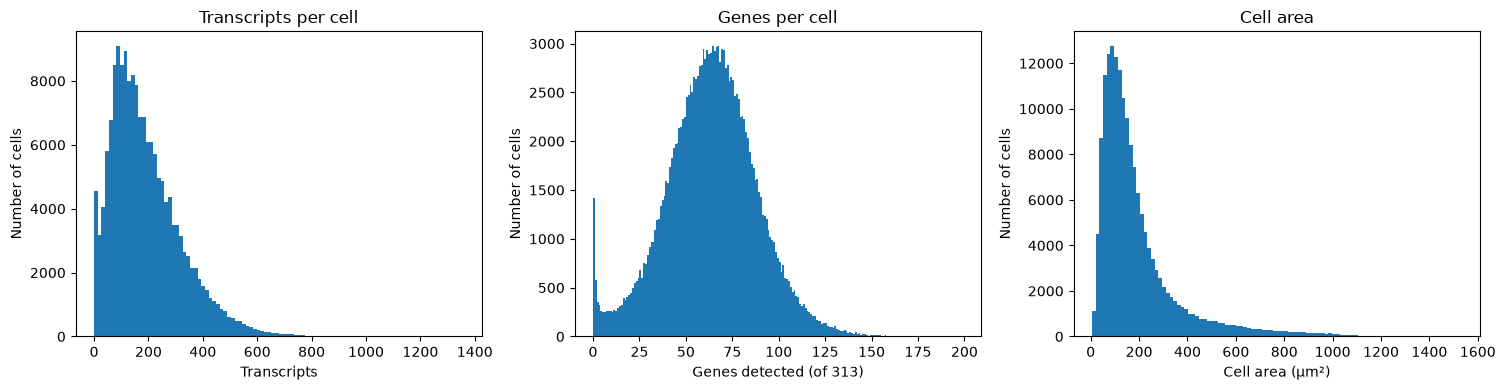

In [10]:
sc.pp.calculate_qc_metrics(adata, percent_top=None, inplace=True)

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
axs[0].hist(adata.obs["total_counts"], bins=100)
axs[0].set(title="Transcripts per cell", xlabel="Transcripts", ylabel="Number of cells")
axs[1].hist(adata.obs["n_genes_by_counts"], bins=np.arange(0, 200))
axs[1].set(title="Genes per cell", xlabel="Genes detected (of 313)", ylabel="Number of cells")
axs[2].hist(adata.obs["cell_area"], bins=100)
axs[2].set(title="Cell area", xlabel="Cell area (µm²)", ylabel="Number of cells")
plt.tight_layout()
plt.show()

- **Transcripts per cell:** peaks around 100 to 150, with a long tail and a spike near 0 (empty outlines).
- **Genes per cell:** centered around 60 to 70 of the 313 genes. One bin per integer avoids artificial gaps, since gene counts are whole numbers.
- **Cell area:** peaks around 100 µm², with a tail past 1,000 µm² (inflated outlines).

### Choosing a minimum transcript count

In [11]:
tc = adata.obs["transcript_counts"]

print(f"Cells with 0 transcripts:    {(tc == 0).sum()}")
print(f"Cells with < 10 transcripts: {(tc < 10).sum()}")
print(f"Cells with < 20 transcripts: {(tc < 20).sum()}")
print(f"Total cells:                 {len(tc)}")

Cells with 0 transcripts:    1417
Cells with < 10 transcripts: 3780
Cells with < 20 transcripts: 5757
Total cells:                 167780


A cutoff trades off two errors: keeping near-empty cells (which form junk clusters) against discarding real cells that naturally carry little RNA. The real decision concerns the 1,977 cells with 10 to 19 transcripts. Small immune cells such as lymphocytes have little RNA and small outlines, and they're central to the question, so a cutoff of 20 risks losing them. Below 10, a cell carries almost no information, and 1,417 cells are completely empty. **I used 10**, which removes 3,780 cells (2.25%).

### Control-probe noise

The noise fraction per cell is noise counts / (real + noise counts).

In [12]:
obs = adata.obs
noise = obs["control_probe_counts"] + obs["control_codeword_counts"]
obs["noise_frac"] = noise / (obs["transcript_counts"] + noise)

print(obs["noise_frac"].describe())
print(f"Cells with more than 5% noise: {(obs['noise_frac'] > 0.05).sum()}")

count    166364.000000
mean          0.000977
std           0.005010
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max           1.000000
Name: noise_frac, dtype: float64
Cells with more than 5% noise: 109


Noise is negligible. The 25th, 50th and 75th percentiles are all 0, the mean is about 0.1%, and only 109 cells (0.07%) exceed 5%. The maximum of 1.0 is a single cell whose only signal was noise. The count is 166,364 rather than 167,780 because empty cells give 0 / 0 (NaN). No separate noise filter is needed.

### Filtering

In [13]:
print(f"Before: {adata.n_obs} cells, {adata.n_vars} genes")

sc.pp.filter_cells(adata, min_counts=10)
sc.pp.filter_genes(adata, min_cells=5)

print(f"After:  {adata.n_obs} cells, {adata.n_vars} genes")

Before: 167780 cells, 313 genes
After:  164000 cells, 313 genes


3,780 cells were removed. No genes were removed: every panel gene appears in at least 5 cells.

### Why counts need normalizing

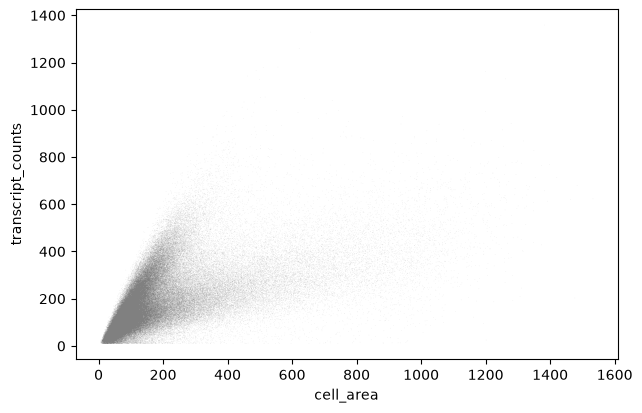

In [14]:
sc.pl.scatter(adata, x="cell_area", y="transcript_counts", alpha=0.2)

Two patterns appear:

- For tightly outlined cells (area below ~250 µm²), transcript counts rise steeply with area. A bigger outline catches more RNA, so without normalization cell size would look like a biological difference.
- For very large outlines (300 to 1,200 µm²), counts barely rise. These outlines mostly cover empty space from the nucleus expansion.

### Normalization and log transform

`normalize_total` rescales every cell to the same total count, so expression becomes comparable between big and small cells. `log1p` (log(x + 1)) compresses the skewed counts, so a few highly expressed genes don't dominate. Raw counts are saved in `layers["counts"]` first. These functions change `adata` in place, so this cell must run only once: running it again would log-transform already-logged values without any warning.

In [15]:
adata.layers["counts"] = adata.X.copy() # saving raw counts first

sc.pp.normalize_total(adata)
sc.pp.log1p(adata)

print("Saved layers:", list(adata.layers.keys()))

Saved layers: ['counts']


In [16]:
raw_totals = np.asarray(adata.layers["counts"].sum(axis=1)).ravel()
print(f"Raw totals for first 5 cells:   {raw_totals[:5]}")
print(f"Max value in normalized X:      {adata.X.max()}")

Raw totals for first 5 cells:   [28. 94. 11. 48. 10.]
Max value in normalized X:      4.775756359100342


The raw totals are preserved in the layer. Cell 3 (9 transcripts) is gone from the first rows, removed by the filter. The largest normalized value is ~4.8, i.e. about 118 counts before the log: one gene in one cell. Normalization scales every cell to the same total (by default the median total, ~164), and the log then compresses the values.

### PCA

PCA compresses the 313 genes into components that capture the main patterns of variation. Many genes move together (for example, several T cell genes rise together), so a few components summarize most of the structure. The `RuntimeWarning` messages come from a numerical routine inside scikit-learn on sparse data; the variance plot and loadings below look as expected, so the components are usable.

/opt/anaconda3/envs/spatial/lib/python3.11/site-packages/sklearn/utils/sparsefuncs.py:740: RuntimeWarning: divide by zero encountered in matmul
  matmat=lambda x: X @ x - offset @ x,
/opt/anaconda3/envs/spatial/lib/python3.11/site-packages/sklearn/utils/sparsefuncs.py:740: RuntimeWarning: overflow encountered in matmul
  matmat=lambda x: X @ x - offset @ x,
/opt/anaconda3/envs/spatial/lib/python3.11/site-packages/sklearn/utils/sparsefuncs.py:740: RuntimeWarning: invalid value encountered in matmul
  matmat=lambda x: X @ x - offset @ x,


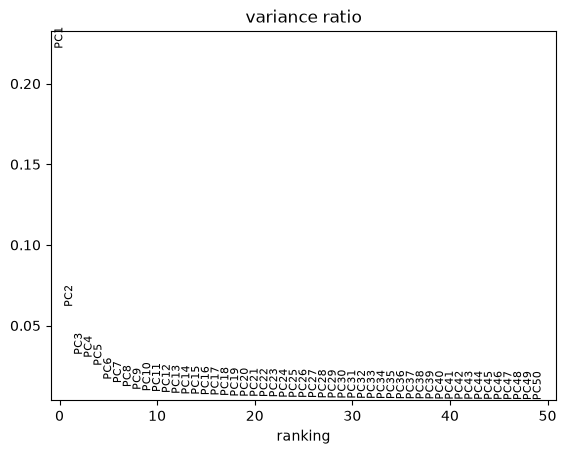

In [17]:
sc.pp.pca(adata)
sc.pl.pca_variance_ratio(adata, n_pcs=50)

PC1 explains ~22% of the variation, PC2 ~6.5%, and after about PC10 to 15 each component adds less than 1% (the "elbow"). I use 20 PCs for the next step: enough to keep the signal, while leaving out the noisier later components.

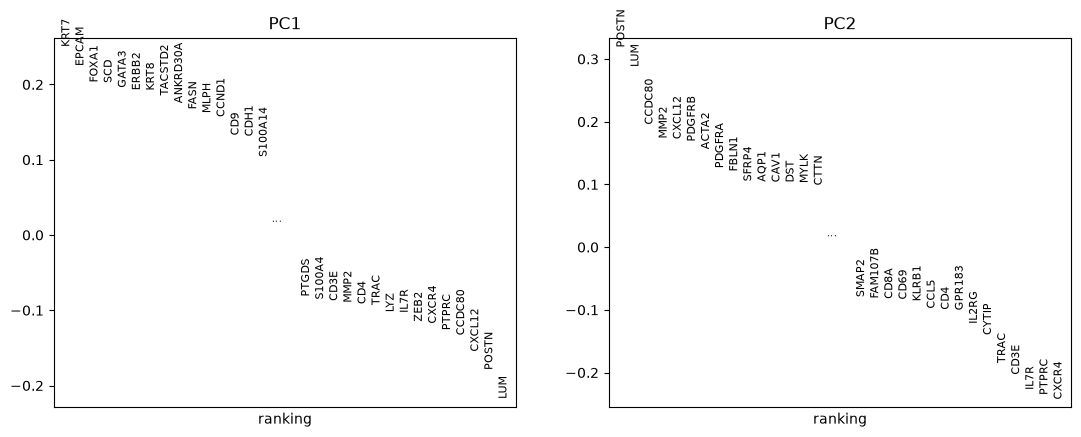

In [18]:
sc.pl.pca_loadings(adata, components="1,2")

The genes with the largest weights show what each component separates:

- **PC1:** epithelial and luminal breast genes (KRT7, KRT8, EPCAM, CDH1, FOXA1, GATA3, ERBB2) at one end, fibroblast (LUM, POSTN) and immune (PTPRC, CD3E, LYZ) genes at the other. **Tumor/epithelial cells vs everything else.**
- **PC2:** fibroblast and vessel genes (POSTN, LUM, PDGFRB, ACTA2, AQP1) vs immune genes (PTPRC, CD3E, CD8A, IL7R). **Stroma vs immune.**

The sign of a component is arbitrary; only which genes group together matters.

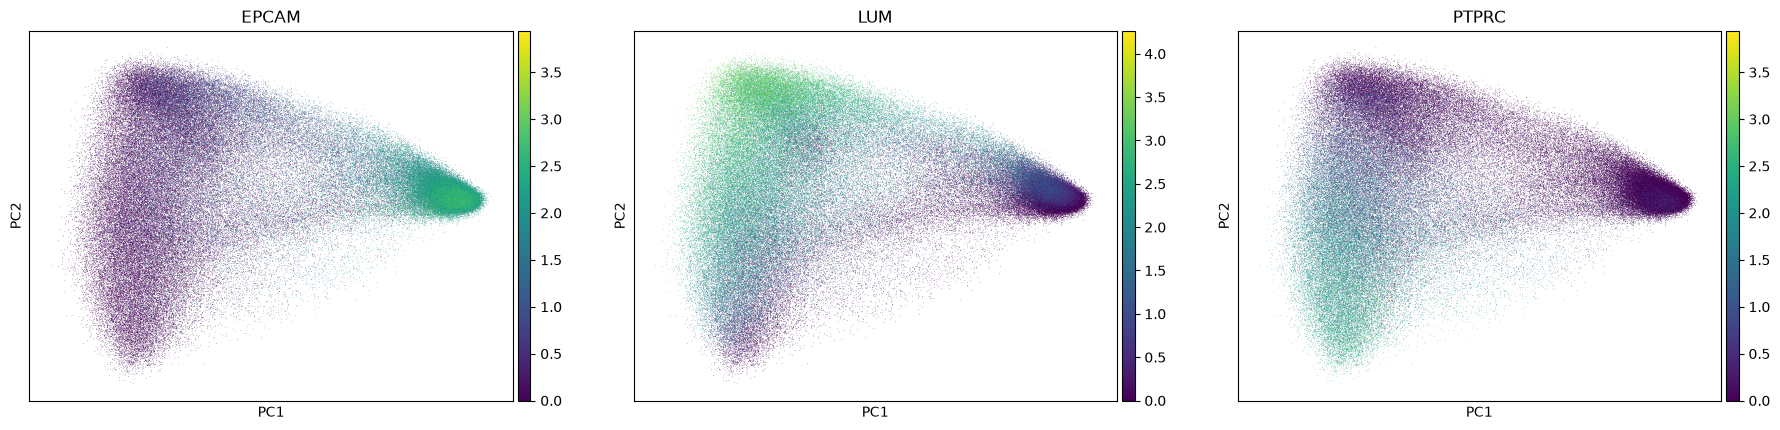

In [19]:
sc.pl.pca(adata, color=["EPCAM", "LUM", "PTPRC"], ncols=3)

On PC1 vs PC2 the cells form a triangle whose corners are the three tissue compartments: tumor/epithelial (EPCAM, right tip), stroma (LUM, top left) and immune (PTPRC, bottom left). Cells along the edges express mixed markers. They may be real intermediate states, or spillover between neighboring cells of different types.

### Neighbor graph and clustering

The neighbor graph links each cell to its 15 most similar cells in PCA space. This is similarity in expression, not physical location. Leiden clustering then finds communities: groups of cells densely linked among themselves. Higher `resolution` gives more, smaller clusters. I used 0.5, a moderate value: it should separate the main cell types without splitting one type into many pieces. A comparison with other values follows the UMAP.

In [20]:
sc.pp.neighbors(adata, n_pcs=20)
print(adata)

AnnData object with n_obs × n_vars = 164000 × 313
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'noise_frac', 'n_counts'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'spatialdata_attrs', 'log1p', 'pca', 'neighbors'
    obsm: 'spatial', 'X_pca'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'distances', 'connectivities'


In [21]:
sc.tl.leiden(adata, resolution=0.5, flavor="igraph", n_iterations=2, key_added="leiden")

print(f"Number of clusters: {adata.obs['leiden'].nunique()}")
print(adata.obs["leiden"].value_counts())

Number of clusters: 11
leiden
1     36261
6     29719
8     23548
5     15650
9     14233
4     12759
3     12472
2      8554
10     4811
7      3596
0      2397
Name: count, dtype: int64


Leiden found **11 clusters**. Each compartment contains several cell types (the immune compartment, for example, includes T cells, B cells and macrophages), so more clusters than compartments is expected. Cluster numbers are only names, not ranks.

UMAP draws the neighbor graph (the 15-nearest-neighbor graph built by `sc.pp.neighbors`) in 2D for viewing. Leiden clustered that graph directly, not the UMAP picture, so a cluster can look split or overlapping on the UMAP and still be one group. Distances between clusters on a UMAP aren't meaningful.

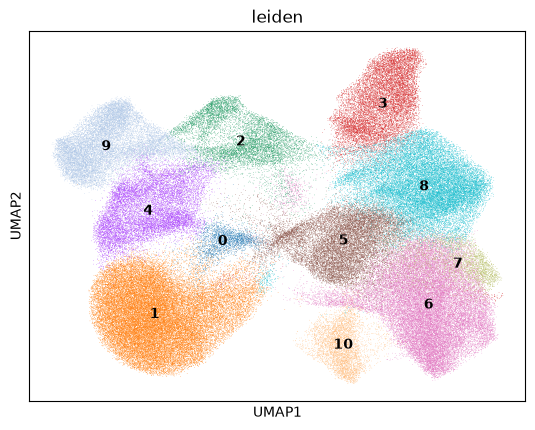

In [22]:
sc.tl.umap(adata)
sc.pl.umap(adata, color="leiden", legend_loc="on data")

### How much does the resolution matter?

There is no single correct resolution. A quick check is to rerun Leiden at a lower and a higher value and see what changes. The extra cluster columns are deleted afterwards so they don't end up in the checkpoint.

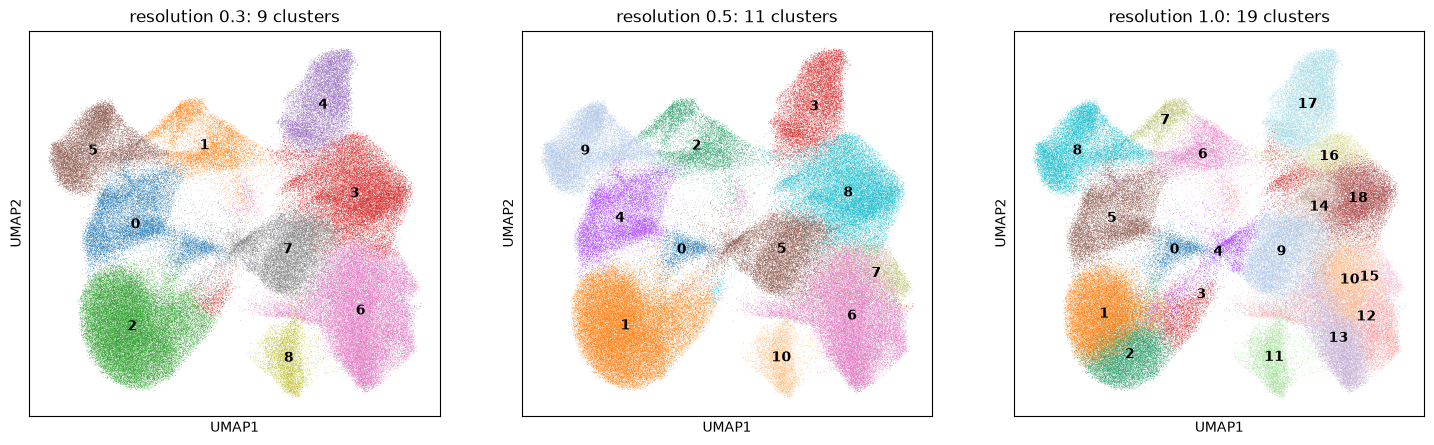

In [23]:
fig, axs = plt.subplots(1, 3, figsize=(18, 5))
for ax, res in zip(axs, [0.3, 0.5, 1.0]):
    key = "leiden" if res == 0.5 else f"leiden_r{res}"
    if res != 0.5:
        sc.tl.leiden(adata, resolution=res, flavor="igraph", n_iterations=2, key_added=key)
    n = adata.obs[key].nunique()
    sc.pl.umap(adata, color=key, legend_loc="on data", ax=ax, show=False,
               title=f"resolution {res}: {n} clusters")
plt.show()

adata.obs.drop(columns=["leiden_r0.3", "leiden_r1.0"], inplace=True)

- **Resolution 0.3 (9 clusters):** two merges happen. B cells (cluster 7 at 0.5) join the T cells, and the low-quality cells (cluster 0) join the ESR1-mid tumor group. Both are a loss: B cells are a separate cell type, and they matter here because T and B cells clustering together may point to immune aggregates. Folding low-quality cells into a tumor group would also hide them inside real data.
- **Resolution 1.0 (19 clusters):** no new cell type appears. Instead, the existing groups split into pieces that sit next to each other on the UMAP: ESR1-low tumor into two, T cells into about four, fibroblasts and endothelial cells into several. These may be real subtypes (for example CD4 and CD8 T cells), but telling them apart would need a marker check for each piece. A few small new clusters (3 and 4) sit between the tumor and macrophage regions, and could be mixed or spillover cells.

So 0.3 merges distinct cell types, and 1.0 mostly splits cell types into sub-pieces. 0.5 is the lowest of the three values that keeps every main cell type separate, which is the level of detail this question needs.

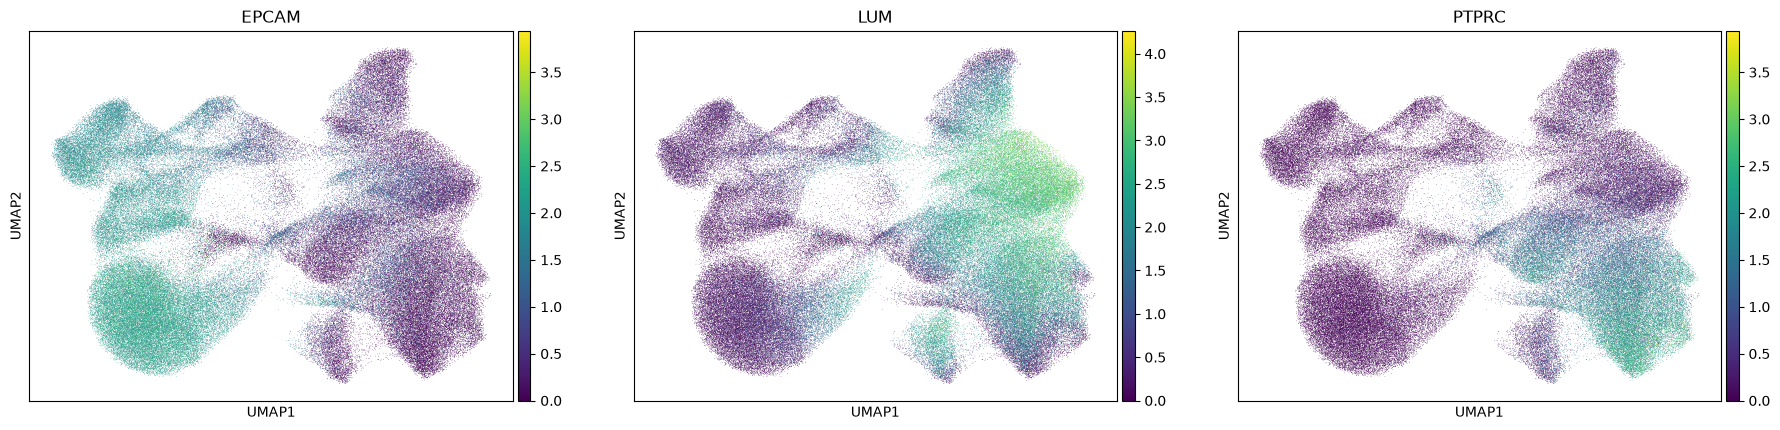

In [24]:
sc.pl.umap(adata, color=["EPCAM", "LUM", "PTPRC"], ncols=3)

- **EPCAM** is high in clusters 1, 4 and 9, and partly in 2.
- **LUM** is highest in 8, clearly present in 3 and 10, and weaker in 5, 6 and 7. A fibroblast gene in immune clusters is unexpected; the immune cells sit in stroma among fibroblasts, so this is most likely spillover from neighboring outlines (Part 1).
- **PTPRC** (CD45, a pan-immune marker) is highest in 6 and 7, moderate in 5, and low in 10. Plasma cells often lose CD45, so a low value there fits Part 3's call.

Three markers can only sort clusters roughly; Part 3 names them properly.

### Checking for technical clusters

If a cluster is defined mainly by very low counts or very large outlines rather than by genes, it's likely technical. Colored plots can hide this (a few extreme cells stretch the color scale), so a per-cluster table is clearer.

In [25]:
qc = adata.obs.groupby("leiden", observed=True)[["transcript_counts", "cell_area", "nucleus_area"]].median()
qc["n_cells"] = adata.obs["leiden"].value_counts()
qc.round(0).sort_values("transcript_counts")

,transcript_counts,cell_area,nucleus_area,n_cells
leiden,,,,
0,22.0,67.0,16.0,2397
7,86.0,92.0,27.0,3596
6,98.0,104.0,26.0,29719
5,141.0,164.0,26.0,15650
3,144.0,151.0,30.0,12472
10,149.0,167.0,28.0,4811
2,164.0,102.0,36.0,8554
8,202.0,301.0,28.0,23548
4,213.0,127.0,54.0,12759


- **Cluster 0** stands out. Its median is 22 transcripts, against 86 to 264 for the other clusters, and it has the smallest cells and nuclei. It's a likely low-quality cluster.
- **Clusters 1, 4 and 9** have nuclei about twice as large as other cells (54 to 71 µm² vs 26 to 36 µm²). Enlarged nuclei are a typical feature of cancer cells, so this supports them being tumor, independently of gene expression.
- **Cluster 8's** outlines are ~11x its nucleus area (301 vs 28 µm²): inflated outlines in sparse stroma.

Saving a checkpoint avoids rerunning the slow steps (neighbors, UMAP) after a restart.

In [26]:
# saving a checkpoint

adata.write_h5ad(DATA_DIR / "adata_processed.h5ad")

## Part 3: Naming the clusters

Clusters are named from combinations of marker genes, because single markers are often shared between cell types (ACTA2, for example, is expressed by both myoepithelial cells and stroma). The marker list below uses canonical markers commonly used for these cell types in breast tissue and single-cell studies. It's checked against the panel first, because a marker that wasn't measured can't be distinguished from one that isn't expressed.

In [27]:
markers = {
    "Tumor / luminal": ["ERBB2", "ESR1", "FOXA1", "GATA3", "KRT7", "KRT8", "EPCAM"],
    "Myoepithelial":   ["KRT14", "KRT5", "ACTA2", "MYH11", "TP63", "MYLK"],
    "Fibroblast":      ["LUM", "POSTN", "COL1A1", "PDGFRA", "PDGFRB"],
    "Endothelial":     ["PECAM1", "VWF", "AQP1", "CAV1"],
    "T cell":          ["CD3E", "TRAC", "CD8A", "CD4", "IL7R", "FOXP3"],
    "B cell":          ["MS4A1", "CD79A"],
    "Macrophage":      ["CD68", "CD163", "LYZ"],
    "Adipocyte":       ["ADIPOQ"],
    "Mast cell":       ["CPA3", "KIT"],
}

in_panel = {}
for cell_type, genes in markers.items():
    found   = [g for g in genes if g in adata.var_names]
    missing = [g for g in genes if g not in adata.var_names]
    print(f"{cell_type:16s} found: {found}   missing: {missing}")
    if found:
        in_panel[cell_type] = found

Tumor / luminal  found: ['ERBB2', 'ESR1', 'FOXA1', 'GATA3', 'KRT7', 'KRT8', 'EPCAM']   missing: []
Myoepithelial    found: ['KRT14', 'KRT5', 'ACTA2', 'MYH11', 'MYLK']   missing: ['TP63']
Fibroblast       found: ['LUM', 'POSTN', 'PDGFRA', 'PDGFRB']   missing: ['COL1A1']
Endothelial      found: ['PECAM1', 'VWF', 'AQP1', 'CAV1']   missing: []
T cell           found: ['CD3E', 'TRAC', 'CD8A', 'CD4', 'IL7R', 'FOXP3']   missing: []
B cell           found: ['MS4A1', 'CD79A']   missing: []
Macrophage       found: ['CD68', 'CD163', 'LYZ']   missing: []
Adipocyte        found: ['ADIPOQ']   missing: []
Mast cell        found: ['CPA3', 'KIT']   missing: []


Only TP63 (myoepithelial) and COL1A1 (fibroblast) are missing from the panel. Both cell types still have four to five other markers.

### Marker dot plot

Dot size shows the fraction of cells in a cluster expressing a gene; color shows its average expression, scaled per gene across clusters (`standard_scale="var"`). For each cluster, I look for the group of columns with large, dark dots.

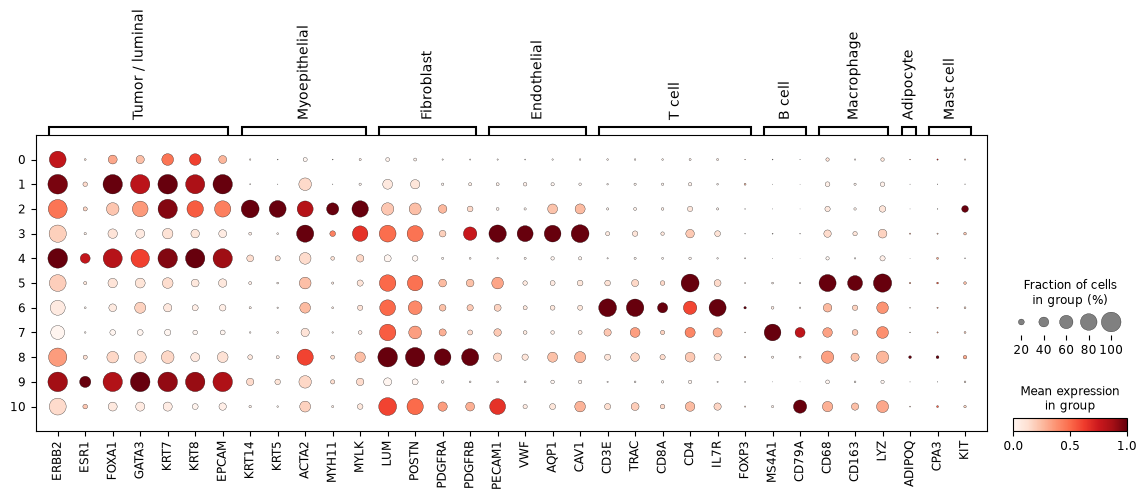

In [28]:
sc.pl.dotplot(adata, in_panel, groupby="leiden", standard_scale="var")

- **1, 4, 9:** tumor/luminal markers (EPCAM, KRT7, KRT8, FOXA1, GATA3, ERBB2). They differ in ESR1 (estrogen receptor).
- **2:** myoepithelial markers (KRT14, KRT5, ACTA2, MYH11, MYLK).
- **3:** endothelial markers (PECAM1, VWF, AQP1, CAV1), plus ACTA2, MYLK and PDGFRB from the muscle-like cells around vessels.
- **5:** macrophage markers (CD68, CD163, LYZ). It also shows CD4, which macrophages express too; it lacks the core T cell markers CD3E and TRAC.
- **6:** T cells (CD3E, TRAC, CD8A, CD4, IL7R).
- **7:** B cells (MS4A1, CD79A).
- **8:** fibroblasts (LUM, POSTN, PDGFRA, PDGFRB).
- **10:** CD79A without MS4A1. This pattern fits **plasma cells** (antibody-producing B cells that switch MS4A1 off).
- **0:** weak, pale dots everywhere; nothing specific.

No cluster corresponds to adipocytes (ADIPOQ) or mast cells (CPA3, KIT).

### Data-driven marker genes

The dot plot only tests the markers I chose. `rank_genes_groups` does the reverse: it ranks the genes most specific to each cluster compared with all other cells (Wilcoxon test). The plot shows the top 4 genes per cluster (names along the top). Rows are reordered by similarity, and the tree on the right groups similar clusters. The dendrogram warning is harmless: scanpy computes the tree automatically.

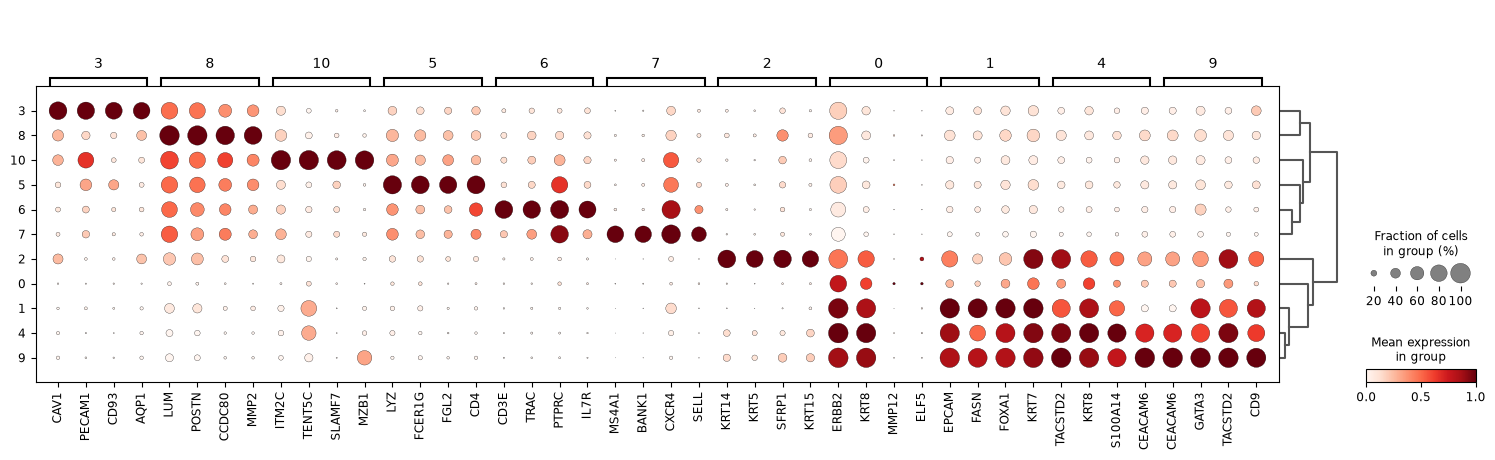

In [29]:
sc.tl.rank_genes_groups(adata, "leiden", method="wilcoxon")
sc.pl.rank_genes_groups_dotplot(adata, n_genes=4, standard_scale="var")

The data-driven genes agree with the marker calls. Cluster 3 (CAV1, PECAM1, CD93, AQP1) is endothelial; 8 (LUM, POSTN) fibroblasts; 5 (LYZ, FCER1G) myeloid; 6 (CD3E, TRAC) T cells; 7 (MS4A1, BANK1) B cells; and 2 (KRT14, KRT5, KRT15, SFRP1) myoepithelial.

- **Cluster 10's** top genes (MZB1, SLAMF7, TENT5C, ITM2C) are classic plasma cell genes. This confirms the call, even though immunoglobulin genes aren't in the panel.
- **Cluster 0's** top genes (ERBB2, KRT8) are weaker in it than in the tumor clusters. It has no gene of its own, so I label it **low quality**.

The tree splits into the same three compartments as PCA: stroma (3, 8), immune (5, 6, 7, 10) and epithelial (0, 1, 2, 4, 9).

### The three tumor clusters

The tumor clusters share the same markers but differ in ESR1. The table below gives each cluster's mean (log-normalized) ESR1 expression and the fraction of its cells with any ESR1 signal.

In [30]:
esr1 = sc.get.obs_df(adata, keys=["leiden", "ESR1"])
esr1 = esr1[esr1["leiden"].isin(["1", "4", "9"])]
esr1.groupby("leiden", observed=True)["ESR1"].agg(
    mean_expression="mean",
    frac_cells_expressing=lambda x: (x > 0).mean(),
).round(2)

,mean_expression,frac_cells_expressing
leiden,,
1,0.09,0.14
4,0.32,0.40
9,0.40,0.47


ESR1 is highest in cluster 9, intermediate in cluster 4 and lowest in cluster 1, matching the dot plot. So the three tumor clusters are named **ESR1-high, ESR1-mid and ESR1-low**. The names are relative to each other within this tumor. They are not clinical **ER status**. In the clinic, a tumor is called ER-positive when at least 1% of its cancer cell nuclei stain for the estrogen receptor protein by immunohistochemistry; ER-positive tumors are treated with hormone therapy. That is a protein measurement on a whole tumor, which RNA counts per cell can't reproduce. Cluster 1 (ESR1-low) also has the strongest ERBB2 (HER2) signal.

cell_type
Tumor (ESR1-low)     36261
T cell               29719
Fibroblast           23548
Macrophage           15650
Tumor (ESR1-high)    14233
Tumor (ESR1-mid)     12759
Endothelial          12472
Myoepithelial         8554
Plasma cell           4811
B cell                3596
Low quality           2397
Name: count, dtype: int64


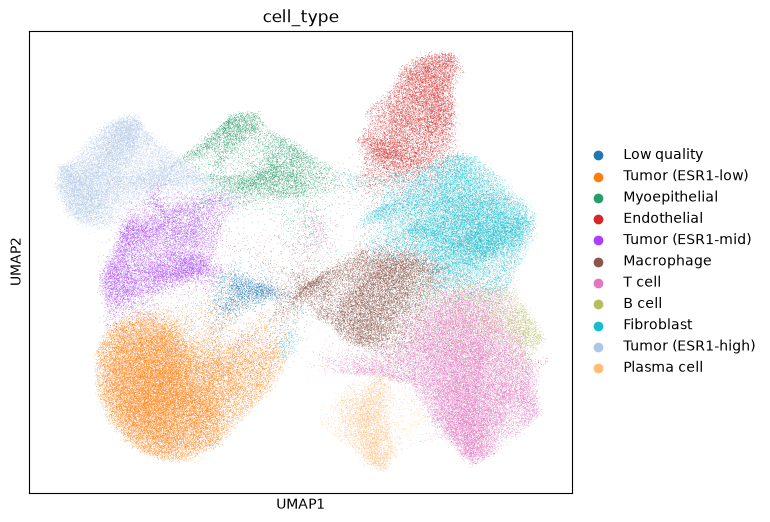

In [31]:
cluster_to_type = {
    "0":  "Low quality",
    "1":  "Tumor (ESR1-low)",
    "2":  "Myoepithelial",
    "3":  "Endothelial",
    "4":  "Tumor (ESR1-mid)",
    "5":  "Macrophage",
    "6":  "T cell",
    "7":  "B cell",
    "8":  "Fibroblast",
    "9":  "Tumor (ESR1-high)",
    "10": "Plasma cell",
}
adata.obs["cell_type"] = adata.obs["leiden"].map(cluster_to_type).astype("category")

print(adata.obs["cell_type"].value_counts())

fig, ax = plt.subplots(figsize=(7, 6))
sc.pl.umap(adata, color="cell_type", ax=ax, show=False)
fig.savefig(FIG_DIR / "umap_cell_types.png", dpi=200, bbox_inches="tight")
plt.show()

Of the 164,000 cells, tumor accounts for ~38.6% (63,253), immune cells ~32.8% (53,776; T cells alone ~18%), stroma ~22.0% (fibroblasts and endothelial cells), myoepithelial cells ~5.2% and low quality ~1.5%. With a third of the cells being immune, the spatial question is a meaningful one.

On the UMAP, myoepithelial cells sit between the tumor and stroma groups. This matches their position in tissue, at the border between the duct and the stroma.

### Comparing with the published labels

The authors annotated the same cells with a single-cell reference. Their labels serve as an independent check on mine.

In [32]:
url = "https://s3.embl.de/spatialdata/spatialdata-sandbox/generated_data/xenium_visium_integration/xenium_rep1_celltype_major.csv"
ref = pd.read_csv(url, index_col=0)

print(ref.shape)
ref.head()

(167780, 2)


,celltype_major,cell_id
0,Normal Epithelial,1
1,Cancer Epithelial,2
2,Endothelial,3
3,Plasmablasts,4
4,Cancer Epithelial,5


In [33]:
print(f"Reference index: {ref.index[:5].tolist()}")
print(f"Reference cell_id column: {ref['cell_id'][:5].tolist()}")
print(f"My cell_id column: {adata.obs['cell_id'][:5].tolist()}")

Reference index: [0, 1, 2, 3, 4]
Reference cell_id column: [1, 2, 3, 4, 5]
My cell_id column: [1, 2, 4, 5, 7]


The reference table's index (0, 1, 2, ...) is only a row number. The real IDs are in its `cell_id` column, which matches mine. Matching on the index would have shifted every label by one row without raising any error. So labels are matched on `cell_id`.

The reference contains all 167,780 cells; each of my 164,000 filtered cells is looked up in it.

In [34]:
ref_labels = ref.set_index("cell_id")["celltype_major"]

adata.obs["published"] = adata.obs["cell_id"].map(ref_labels)

print("Fraction of cells matched:", adata.obs["published"].notna().mean())
print(adata.obs["published"].value_counts())

Fraction of cells matched: 1.0
published
Cancer Epithelial    55144
T-cells              26704
CAFs                 24526
Myeloid              19505
Normal Epithelial    17203
Endothelial          11134
Plasmablasts          3394
B-cells               3290
PVL                   3100
Name: count, dtype: int64


All cells matched. In the published labels, **CAFs** are cancer-associated fibroblasts, **Myeloid** includes macrophages, **PVL** are perivascular-like cells (pericytes and smooth muscle around vessels), **Plasmablasts** are antibody-producing B-lineage cells, and **Normal Epithelial** includes myoepithelial and normal luminal cells. The published labels have no low-quality category.

In [35]:
adata.write_h5ad(DATA_DIR / "adata_annotated.h5ad")

In the table below, each row shows how the cells I gave one label were labeled by the authors (rows add up to 1).

In [36]:
comparison = pd.crosstab(
    adata.obs["cell_type"],
    adata.obs["published"],
    normalize="index",
).round(2)

comparison

published,B-cells,CAFs,Cancer Epithelial,Endothelial,Myeloid,Normal Epithelial,PVL,Plasmablasts,T-cells
cell_type,,,,,,,,,
Low quality,0.08,0.01,0.25,0.19,0.04,0.07,0.18,0.16,0.03
Tumor (ESR1-low),0.00,0.00,0.89,0.00,0.01,0.09,0.00,0.00,0.00
Myoepithelial,0.00,0.01,0.01,0.00,0.04,0.93,0.01,0.00,0.00
Endothelial,0.00,0.03,0.00,0.79,0.02,0.00,0.14,0.00,0.01
Tumor (ESR1-mid),0.00,0.00,0.82,0.00,0.00,0.18,0.00,0.00,0.00
Macrophage,0.01,0.08,0.01,0.01,0.88,0.00,0.00,0.00,0.01
T cell,0.01,0.05,0.00,0.01,0.06,0.00,0.00,0.00,0.86
B cell,0.69,0.07,0.00,0.00,0.17,0.00,0.00,0.01,0.06
Fibroblast,0.01,0.85,0.01,0.01,0.07,0.01,0.02,0.00,0.01


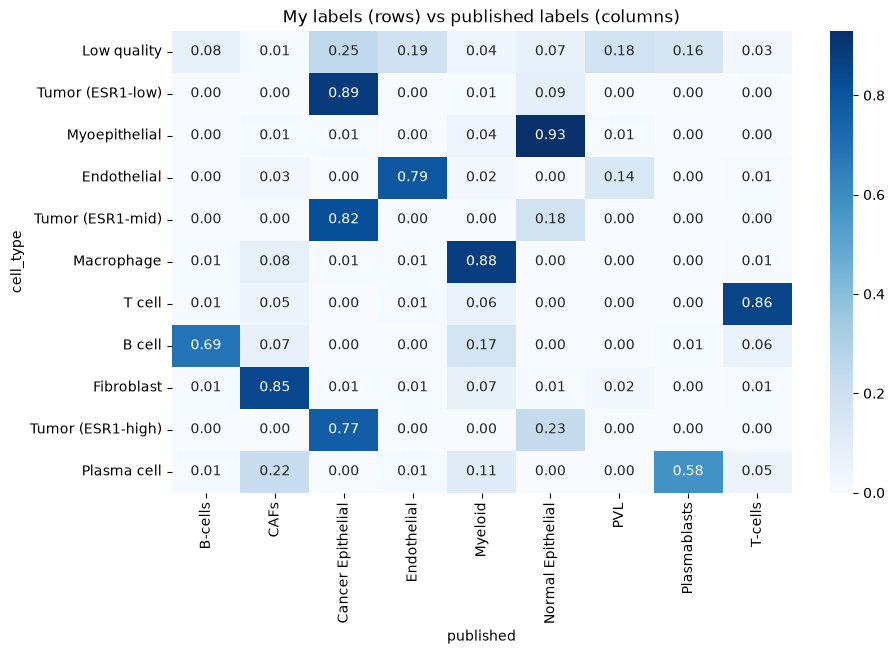

In [37]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(comparison, annot=True, cmap="Blues", fmt=".2f", ax=ax)
ax.set_title("My labels (rows) vs published labels (columns)")
fig.savefig(FIG_DIR / "label_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

- **Agreement is 77 to 93% for most cell types:** myoepithelial 93% (as Normal Epithelial), tumor ESR1-low 89%, macrophage 88%, T cell 86%, fibroblast 85%. Endothelial is 79%, plus 14% PVL, consistent with the perivascular markers seen in that cluster.
- **Low quality:** these cells are scattered across almost every published category, with none above 25%. A real cell type would land mostly in one column, so this supports treating cluster 0 as technical.
- **Tumor vs normal epithelium:** 9%, 18% and 23% of my ESR1-low, -mid and -high tumor cells are labeled Normal Epithelial by the authors (~8,800 cells in total). The likely reason: healthy luminal cells lining normal ducts express the same genes used here to call tumor (ESR1, EPCAM, KRT8, FOXA1, GATA3). With these markers alone, a normal luminal cell and an ER-positive tumor cell look alike, so some normal cells probably ended up in my tumor groups. This affects the ESR1-high group most (23%), which makes sense since normal luminal cells are themselves ESR1-positive.
- **Weaker agreement** for plasma cells (58%, with 22% labeled CAFs) and B cells (69%) likely reflects spillover in stroma and in immune-dense areas.

## Part 4: Where are the immune cells?

So far, only gene expression has been used. Here the cell positions in `obsm["spatial"]` are used to ask where each cell type sits and which cell types are neighbors.

In [38]:
xy = adata.obsm["spatial"]

print(f"Shape: {xy.shape}")
print(f"First 3 cells:\n {xy[:3]}")
print(f"x range: {xy[:, 0].min()} to {xy[:, 0].max()}")
print(f"y range: {xy[:, 1].min()} to {xy[:, 1].max()}")

Shape: (164000, 2)
First 3 cells:
 [[847.25991211 326.19136505]
 [826.34199524 328.03182983]
 [824.22840881 334.25264282]]
x range: 2.1325160980224607 to 7523.086865234375
y range: 3.642256760597229 to 5474.379345703125


The coordinate ranges (0 to ~7,523 and 0 to ~5,474) match the image size converted to micrometers (35,416 × 0.2125 ~ 7,526; 25,778 × 0.2125 ~ 5,478). So cell positions are in µm, while the image is in pixels. Distances below are therefore real distances in the tissue.

### Cell types on the tissue

The low-quality cells are removed, so they aren't counted as neighbors. For a first view, the cell types are grouped into compartments. The y-axis is flipped so the map matches the image orientation.

161603 cells kept


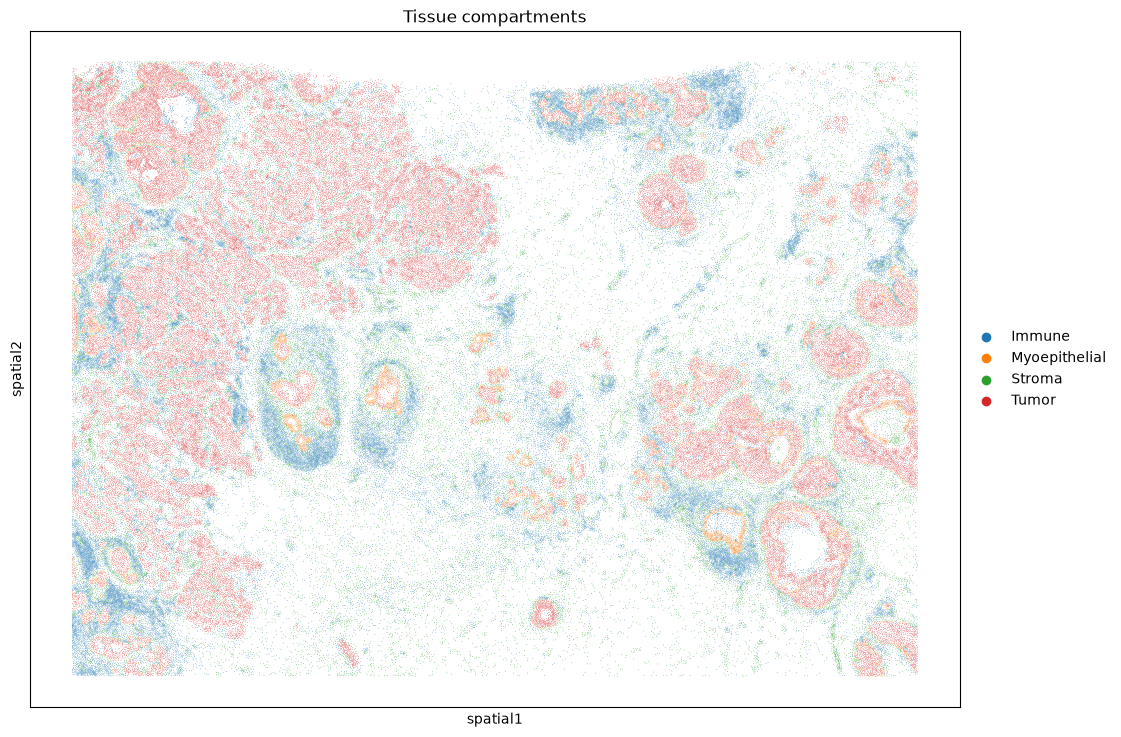

In [39]:
compartment_map = {
    "Tumor (ESR1-low)": "Tumor", "Tumor (ESR1-mid)": "Tumor", "Tumor (ESR1-high)": "Tumor",
    "T cell": "Immune", "B cell": "Immune", "Plasma cell": "Immune", "Macrophage": "Immune",
    "Fibroblast": "Stroma", "Endothelial": "Stroma",
    "Myoepithelial": "Myoepithelial",
    "Low quality": "Low quality",
}
adata.obs["compartment"] = adata.obs["cell_type"].map(compartment_map).astype("category")

ad = adata[adata.obs["cell_type"] != "Low quality"].copy()
print(ad.n_obs, "cells kept")

compartment_colors = {"Tumor": "#D62728", "Immune": "#1F77B4", "Stroma": "#2CA02C", "Myoepithelial": "#FF7F0E"}

fig, ax = plt.subplots(figsize=(12, 9))
sc.pl.embedding(ad, basis="spatial", color="compartment", palette=compartment_colors, s=1, ax=ax, show=False)
ax.invert_yaxis()
ax.set_aspect("equal")
ax.set_title("Tissue compartments")
fig.savefig(FIG_DIR / "tissue_compartments.png", dpi=200, bbox_inches="tight")
plt.show()

Two tumor patterns are visible:

- **Left:** large continuous tumor sheets with no myoepithelial cells around them, consistent with invasive carcinoma.
- **Right and center:** round, duct-like tumor nests, often with a hollow center. Some are surrounded by an intact myoepithelial ring (orange), consistent with DCIS.

Immune cells mostly form rims around the tumor nests, strands between the tumor sheets, and separate immune-rich patches in the stroma, rather than mixing into tumor regions. This suggests immune exclusion, but it's a visual impression; the next steps measure it.

### Neighborhood enrichment

A spatial graph links each cell to its physical neighbors (Delaunay triangulation of the cell centers). For every pair of cell types, `nhood_enrichment` counts how often they are neighbors, and compares that with 200 random shufflings of the labels (positions kept fixed). The result is a z-score: positive means neighbors more often than chance, negative means less often.

Z-scores grow with the number of cells involved, so the **sign** is more informative than the size when comparing pairs. The `FutureWarning` only says that `spatial_neighbors` will be renamed in squidpy 1.9; it doesn't affect the result.

INFO     Creating graph using `None` transform and `1` libraries.                                                  


/var/folders/yh/473l5z4x3n52gcvt8gfnwc7w0000gn/T/ipykernel_72168/382316478.py:1: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(ad, coord_type="generic", delaunay=True)
  0%|          | 0/200 [00:00<?, ?/s]/opt/anaconda3/envs/spatial/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/opt/anaconda3/envs/spatial/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
100%|██████████| 200/200 [00:04<00:00, 42.48/s] 


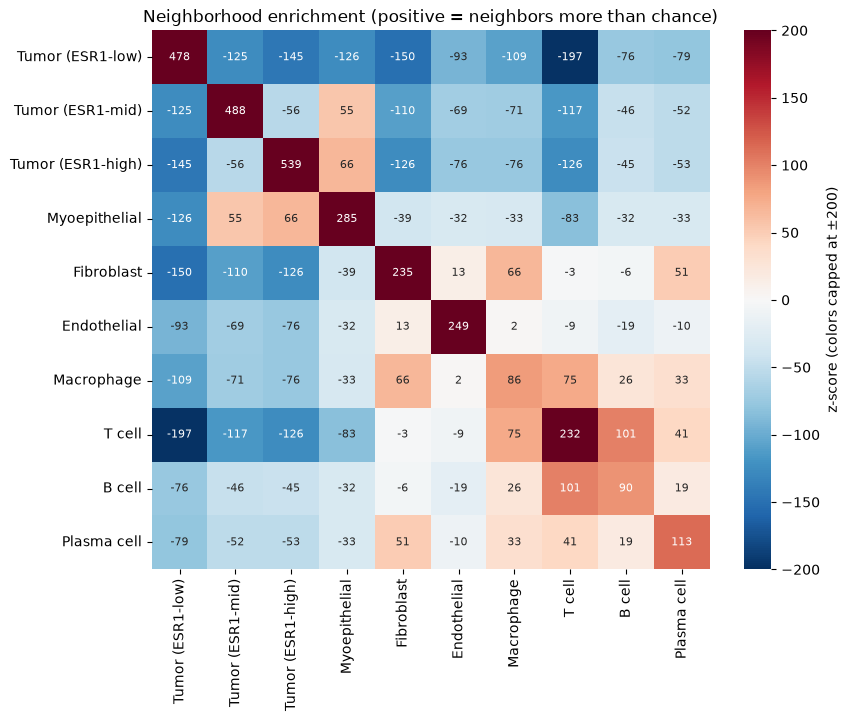

In [40]:
sq.gr.spatial_neighbors(ad, coord_type="generic", delaunay=True)
sq.gr.nhood_enrichment(ad, cluster_key="cell_type", n_perms=200, seed=0)

cats = ad.obs["cell_type"].cat.categories
z = pd.DataFrame(ad.uns["cell_type_nhood_enrichment"]["zscore"], index=cats, columns=cats)

order = ["Tumor (ESR1-low)", "Tumor (ESR1-mid)", "Tumor (ESR1-high)", "Myoepithelial",
         "Fibroblast", "Endothelial", "Macrophage", "T cell", "B cell", "Plasma cell"]
z = z.loc[order, order]

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(z, cmap="RdBu_r", center=0, vmin=-200, vmax=200, annot=True, fmt=".0f",
            annot_kws={"size": 8}, cbar_kws={"label": "z-score (colors capped at ±200)"}, ax=ax)
ax.set_title("Neighborhood enrichment (positive = neighbors more than chance)")
fig.savefig(FIG_DIR / "neighborhood_enrichment.png", dpi=200, bbox_inches="tight")
plt.show()

- **All immune cell types are depleted next to all tumor groups** (negative z-scores).
- **T cells are enriched next to other immune cells** (T cells +232, B cells +101, macrophages +75, plasma cells +41), but not next to fibroblasts (= −3). T and B cells clustering together is consistent with immune aggregates, possibly tertiary lymphoid structures (organized immune clusters that form in some tumors). Confirming that would need a closer look at their structure.
- **Macrophages** also avoid tumor, but less strongly, and are enriched next to fibroblasts (+66), so they are spread more through the stroma.
- **Myoepithelial cells** are enriched next to ESR1-high (+66) and ESR1-mid (+55) tumor, but depleted next to ESR1-low tumor (−126). Together with the map, this suggests that ESR1-high and ESR1-mid tumor sits in DCIS-like ducts with an intact myoepithelial layer, while ESR1-low tumor forms the invasive-like sheets.

ESR1-low tumor has the most negative z-score with T cells (−197). But it's also by far the largest tumor group, so this number can't be read as "T cells avoid it most"; that is tested directly in the regional check below.

### Distance from each cell type to the nearest tumor cell

A more intuitive measure: for every non-tumor cell, the distance (µm) to the closest tumor cell. A KD-tree finds nearest neighbors quickly. The table gives the median distance and the fraction of cells within 20 µm of tumor (about one or two cell widths, i.e. essentially touching).

In [41]:
xy = ad.obsm["spatial"]
is_tumor = (ad.obs["compartment"] == "Tumor").values

tree = cKDTree(xy[is_tumor])          # a fast lookup structure built from tumor cell positions
dist, _ = tree.query(xy)              # for every cell: distance (µm) to the nearest tumor cell
ad.obs["dist_to_tumor"] = dist

non_tumor = ad.obs[~is_tumor]
summary = non_tumor.groupby("cell_type", observed=True)["dist_to_tumor"].agg(
    median_um="median",
    within_20um=lambda d: (d <= 20).mean(),
)
summary.round(2).sort_values("median_um")

,median_um,within_20um
cell_type,,
Myoepithelial,11.58,0.84
Endothelial,39.59,0.29
Macrophage,58.46,0.25
T cell,71.59,0.16
Plasma cell,80.69,0.07
Fibroblast,90.80,0.17
B cell,125.17,0.03


- **Myoepithelial cells are closest** (median ~12 µm, 84% within 20 µm). This is expected, since they wrap tumor-filled ducts.
- **Endothelial cells** are next (~40 µm), consistent with tumors recruiting blood vessels.
- **Macrophages** (~58 µm, 25% within 20 µm) sit closer to tumor than **T cells** (~72 µm, 16%).
- **B cells** are furthest (~125 µm, 3%).
- **Fibroblasts** (~91 µm) give a rough baseline for a stromal cell. T cells sit closer to tumor than that, which suggests they gather toward tumor borders, but only 16% are within 20 µm of a tumor cell.

Overall, immune cells are found near the tumor but rarely in contact with it.

### Regional check: invasive-like vs DCIS-like tumor

Distance to the nearest tumor cell isn't a fair way to compare tumor groups, because the largest group is more likely to be nearest by chance. Instead, the question is asked from each tumor cell's point of view: **how many T cells are within 30 µm of it?** Averaging per tumor cell removes the effect of group size.

In [42]:
radius = 30  # µm

xy = ad.obsm["spatial"]
ct = ad.obs["cell_type"]

t_tree = cKDTree(xy[(ct == "T cell").values])

tumor_types = ["Tumor (ESR1-low)", "Tumor (ESR1-mid)", "Tumor (ESR1-high)"]
is_tumor_cell = ct.isin(tumor_types).values

# number of T cells within `radius` µm of each tumor cell
t_counts = t_tree.query_ball_point(xy[is_tumor_cell], r=radius, return_length=True)

tumor_df = pd.DataFrame({
    "tumor_type": ct[is_tumor_cell].astype(str).values,
    "t_cells_within_30um": t_counts,
})

regional = tumor_df.groupby("tumor_type")["t_cells_within_30um"].agg(
    n_tumor_cells="size",
    mean_t_cells="mean",
    frac_with_any_t=lambda c: (c > 0).mean(),
)
regional.round(3)

,n_tumor_cells,mean_t_cells,frac_with_any_t
tumor_type,,,
Tumor (ESR1-high),14233,0.467,0.254
Tumor (ESR1-low),36261,0.794,0.371
Tumor (ESR1-mid),12759,0.573,0.264


**Invasive-like ESR1-low tumor has the most T cell contact:** 37% of its cells have at least one T cell within 30 µm (mean 0.79), compared with ~26% for ESR1-mid and ~25% for ESR1-high.

This also shows why the neighborhood z-scores needed care: ESR1-low had the most negative z-score with T cells, yet per tumor cell it has the most contact. The size of that z-score reflected the size of the group.

To check that this isn't an artifact of the 30 µm radius, the same measure is repeated at 20 and 50 µm:

In [43]:
robustness = {}
for r in [20, 30, 50]:
    counts = t_tree.query_ball_point(xy[is_tumor_cell], r=r, return_length=True)
    df = pd.DataFrame({"tumor_type": ct[is_tumor_cell].astype(str).values, "n": counts})
    robustness[f"{r} µm"] = df.groupby("tumor_type")["n"].apply(lambda c: (c > 0).mean())

pd.DataFrame(robustness).round(3)

,20 µm,30 µm,50 µm
tumor_type,,,
Tumor (ESR1-high),0.116,0.254,0.536
Tumor (ESR1-low),0.178,0.371,0.714
Tumor (ESR1-mid),0.114,0.264,0.564


The ranking holds at every radius: ESR1-low tumor has the most T cell contact (18%, 37% and 71% of cells), while ESR1-mid and ESR1-high stay similar to each other and lower. At 50 µm most tumor cells in every group have a T cell nearby, which is too wide a window to mean contact, so 30 µm (a few cell widths) is the main measure.

The map below shows the three tumor groups and T cells; all other cells are light gray.

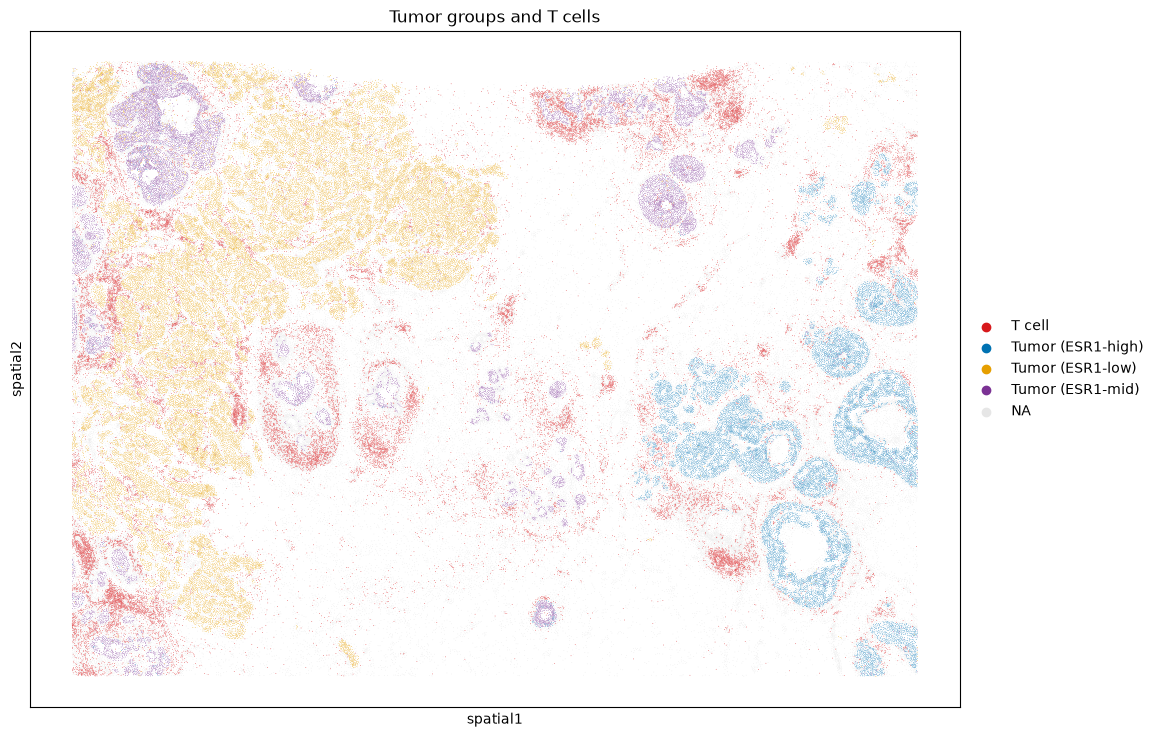

In [44]:
show = tumor_types + ["T cell"]
tumor_colors = {
    "Tumor (ESR1-low)": "#E69F00",   # orange
    "Tumor (ESR1-mid)": "#7B3294",   # purple
    "Tumor (ESR1-high)": "#0072B2",  # blue
    "T cell": "#D7191C",             # red
}
# scanpy needs a color for every category; cells outside `show` are drawn in na_color anyway
palette = {c: "#E6E6E6" for c in ad.obs["cell_type"].cat.categories} | tumor_colors

fig, ax = plt.subplots(figsize=(12, 9))
sc.pl.embedding(ad, basis="spatial", color="cell_type", groups=show, palette=palette,
                na_color="#E6E6E6", s=1, ax=ax, show=False)
ax.invert_yaxis()
ax.set_aspect("equal")
ax.set_title("Tumor groups and T cells")
fig.savefig(FIG_DIR / "tumor_groups_t_cells.png", dpi=200, bbox_inches="tight")
plt.show()

ESR1-low tumor forms the large sheets on the left, with T cells running in strands between them and along their edges. ESR1-mid and ESR1-high tumor sit in round, duct-like nests, with T cells mostly gathered around the outside. This fits the idea that the myoepithelial layer around DCIS-like ducts acts as a physical barrier, while T cells can follow stromal strands into invasive tumor. Even in the invasive-like regions, though, 63% of tumor cells have no T cell within 30 µm.

## Conclusions

**Do immune cells infiltrate the tumor?** In this section, mostly not. Every immune cell type was found next to tumor cells less often than expected by chance. T cells sat a median of ~72 µm from the nearest tumor cell, and only 16% were within 20 µm. They gathered at tumor borders and in immune aggregates with B cells and macrophages, rather than entering tumor regions. This pattern is often described as **immune exclusion**.

The degree of exclusion differed by region. DCIS-like tumor nests, wrapped by myoepithelial cells, had the least T cell contact (~25% of tumor cells with a T cell within 30 µm). Invasive-like tumor sheets had more (37%), but most of their cells still had no T cell nearby.

**Limitations**

- One tissue section from one patient. The results describe this sample, not breast cancer in general, and no statistical test was applied to the regional differences.
- Nucleus-expansion segmentation inflates outlines in sparse tissue (6.6% of cells are at least 20x their nucleus area). Spillover may blur cell identities exactly at the tumor–immune borders being measured.
- Annotation used a 313-gene panel and marker genes. Normal luminal cells and ER-positive tumor cells share markers, so some normal epithelium (~8,800 cells) is likely included in the tumor groups, especially ESR1-high.
- The ESR1 groups are relative expression levels within this tumor, not clinical ER status. Linking them to DCIS and invasive disease rests on spatial patterns, not on pathology review.

**Possible next steps**

- Re-segment with a transcript-aware method (e.g. Baysor or Proseg) and test whether the immune-exclusion results hold.
- Repeat on the second replicate section (`xenium_rep2_io`).
- Compare with pathologist annotations of DCIS and invasive regions.